# How does a computer find the lowest point of a landscape it can't see?

The companion notebook to `notes.pdf`. You feel a slope from two heights, walk down a one-knob valley in exact
fractions, try five step sizes and see the one number that decides them, walk a two-knob landscape into a deep
valley (or a shallow one, or a small dip), find the step size past which it never settles, let gradient descent
fit a line to 12 apartments with the knobs chosen well and chosen badly, and then take the same fit
apart the ways real training does: one apartment per step, four per step, a heavy ball, and Adam.

Nothing here is timed: every number is a position, a slope, a height or a count of steps, the same on every
machine. Standard library only; matplotlib is optional (every picture is also printed as numbers). It runs in a
few seconds. Set `FULL = True` to run the long walk of section 6 all the way (738,888 steps, a few
seconds more).

In [1]:
FULL = False                       # True: the long walk of section 6 runs to the end (a few seconds more)
LONG_CAP = 2_000_000 if FULL else 100_000

import math
from fractions import Fraction as Fr

try:
    import matplotlib.pyplot as plt
except ImportError:                # the pictures are optional; their numbers are printed too
    plt = None

## 1. One knob: feeling the slope

The valley is \(f(x) = (x - 2)^2 + 1\), bottom at 2. The walker stands at
6 and can only ask for heights. Two heights a tiny step \(h\) apart, divided by the distance
between them, give the slope. Watch it settle on 8 as \(h\) shrinks: the two-sided
measurement is exact for this curve at every \(h\), the one-sided one (only to the right) only gets close.

In [2]:
def f(x):
    return (x - 2) ** 2 + 1


def slope(x):                      # the formula (the derivative)
    return 2 * (x - 2)


x = 6
for h in [1, 0.1, 0.01, 0.001]:
    two_sided = (f(x + h) - f(x - h)) / (2 * h)
    one_sided = (f(x + h) - f(x)) / h
    print(f"h = {h:<6} two heights either side: {two_sided:.6f}   right side only: {one_sided:.6f}")
print("the formula 2 * (x - 2):", slope(x))

h = 1      two heights either side: 8.000000   right side only: 9.000000
h = 0.1    two heights either side: 8.000000   right side only: 8.100000
h = 0.01   two heights either side: 8.000000   right side only: 8.010000
h = 0.001  two heights either side: 8.000000   right side only: 8.001000
the formula 2 * (x - 2): 8


The rule is \(x_{\text{new}} = x - \eta \cdot \text{slope}\). With \(\eta = 1/4\) our run went
6, 4, 3, 2.5,
2.25. In exact fractions you can see each step halve the distance to the bottom, and the step
shrink with the slope, with no rounding anywhere.

In [3]:
x, eta = Fr(6), Fr(1, 4)
print(f"{'step':>4} {'x':>8} {'slope':>6} {'step taken':>10} {'distance to 2':>14}")
for k in range(7):
    s = slope(x)
    print(f"{k:>4} {str(x):>8} {str(s):>6} {str(eta * s):>10} {str(abs(x - 2)):>14}")
    x = x - eta * s

step        x  slope step taken  distance to 2
   0        6      8          2              4
   1        4      4          1              2
   2        3      2        1/2              1
   3      5/2      1        1/4            1/2
   4      9/4    1/2        1/8            1/4
   5     17/8    1/4       1/16            1/8
   6    33/16    1/8       1/32           1/16


## 2. The step size: one number decides

One step does \(x - 2 \to (1 - 2\eta)(x - 2)\): it multiplies the distance to the bottom by \(1 - 2\eta\). Our run
counted the steps to get within 0.01 of the bottom: 57
for \(\eta = 1/20\), 9 for \(1/4\),
9 for \(3/4\), and never for 1 (it bounces between
6 and -2) or \(11/10\) (it flies off).

eta = 1/20  factor 1 - 2*eta = 9/10  first positions 6, 5.6, 5.24, 4.916, 4.6244, 4.36196       steps to 0.01: 57
eta = 1/4   factor 1 - 2*eta = 1/2   first positions 6, 4, 3, 2.5, 2.25, 2.125                  steps to 0.01: 9
eta = 3/4   factor 1 - 2*eta = -1/2  first positions 6, 0, 3, 1.5, 2.25, 1.875                  steps to 0.01: 9
eta = 1     factor 1 - 2*eta = -1    first positions 6, -2, 6, -2, 6, -2                        steps to 0.01: never
eta = 11/10 factor 1 - 2*eta = -6/5  first positions 6, -2.8, 7.76, -4.912, 10.2944, -7.95328   steps to 0.01: never


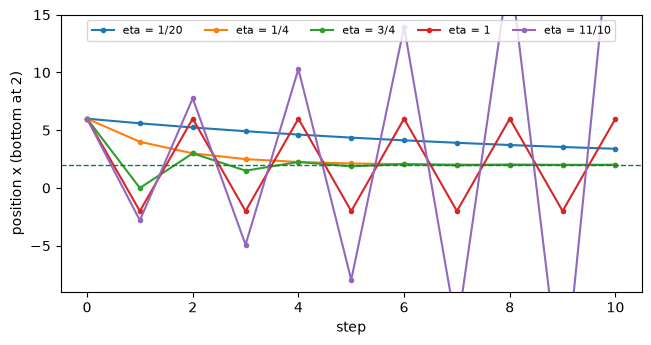

In [4]:
def steps_within(eta, tol=Fr(1, 100), cap=10_000):
    x = Fr(6)
    for k in range(cap + 1):
        if abs(x - 2) <= tol:
            return k
        if abs(x - 2) > 10 ** 6:
            return None
        x = x - eta * slope(x)
    return None


RATES = [Fr(1, 20), Fr(1, 4), Fr(3, 4), Fr(1), Fr(11, 10)]
walks = {}
for eta in RATES:
    xs = [Fr(6)]
    for _ in range(10):
        xs.append(xs[-1] - eta * slope(xs[-1]))
    walks[eta] = xs
    n = steps_within(eta)
    print(f"eta = {str(eta):<5} factor 1 - 2*eta = {str(1 - 2 * eta):<5} "
          f"first positions {', '.join(f'{float(v):g}' for v in xs[:6]):<42} steps to 0.01: {'never' if n is None else n}")

if plt:
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    for eta, xs in walks.items():
        ax.plot(range(len(xs)), [float(v) for v in xs], "o-", ms=3, label=f"eta = {eta}")
    ax.axhline(2, color="#1E7346", lw=1, ls="--")
    ax.set_ylim(-9, 15)
    ax.set_xlabel("step")
    ax.set_ylabel("position x (bottom at 2)")
    ax.legend(fontsize=8, ncol=5, loc="upper center")
    plt.show()

## 3. Two knobs: the gradient, two valleys and a dip

The landscape of the video: a gentle bowl and eight bumps, two of them valleys, one a small dip, the rest hills.
At the start \((-1.9, 2.5)\) the two slopes were \(-0.227\) and
\(0.299\): the gradient, an arrow of length 0.3754 pointing uphill.
The walk steps against it. With \(\eta = 0.5\) our run reached the deep bottom (height
-1.024) in 36 steps; from \((-2.6, 0.2)\)
it settled in the shallow one (height -0.489) in 12, and from
\((0.6, -2.6)\) it stopped in the small dip (height -0.248)
after 19. Watch the step lengths of the first walk: they shrink on a flat shelf, then grow as it
drops.

slopes at the start: -0.227312, 0.298785   felt from nearby heights: -0.227312, 0.298785
the gradient's length (steepness): 0.375424
eta 0.5 from (-1.9, 2.5): 36 steps, ends at (1.2456, 0.6681), height -1.0237
eta 0.5 from (-2.6, 0.2): 12 steps, ends at (-1.4315, -1.1457), height -0.4886
eta 0.5 from (0.6, -2.6): 19 steps, ends at (0.4923, -0.9381), height -0.2485
step lengths of the first walk: 0.19 0.17 0.16 0.15 0.13 0.12 0.11 0.10 0.10 0.10 0.10 0.10 0.10 0.11 0.11 0.10 0.08 0.06 0.05 0.05 0.05 0.06 0.07 0.09 0.12 0.17 0.24 0.35 0.49 0.31 0.08 0.03 0.01 0.01 0.00 0.00


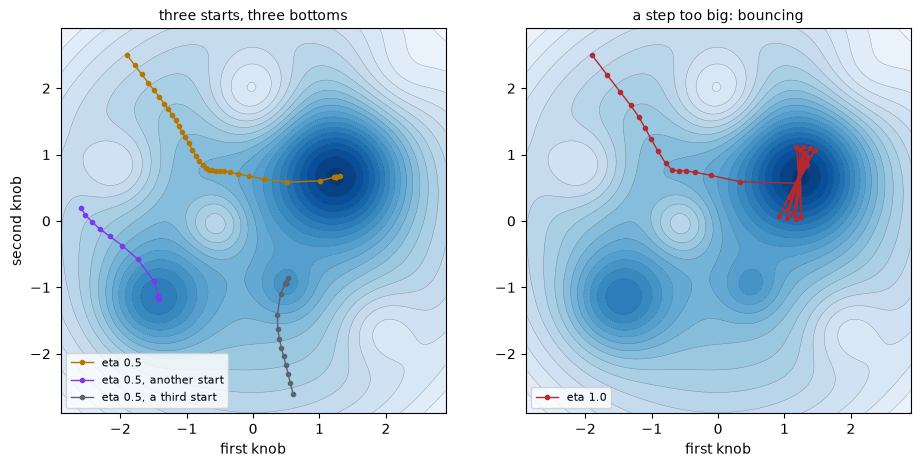

In [5]:
BOWL = 0.06
BUMPS = [(-1.15, 1.3, 0.7, 0.85), (-0.70, -1.5, -1.2, 0.55), (0.60, 0.0, 1.9, 0.45), (0.45, -0.55, -0.05, 0.22),
         (0.40, -2.0, 0.8, 0.35), (0.35, 1.9, -1.6, 0.40), (-0.30, 0.5, -1.0, 0.18), (0.25, 2.2, 2.2, 0.50)]
# (height, x, y, width^2): deep valley, shallow valley, big hill, round middle hill, left hill, front-right hill,
# the small dip, a far rise. The land drawn in the video is the square |x|, |y| <= 2.9.
START, OTHER_START, TRAP_START = (-1.9, 2.5), (-2.6, 0.2), (0.6, -2.6)


def land(x, y):
    return BOWL * (x * x + y * y) + sum(a * math.exp(-((x - cx) ** 2 + (y - cy) ** 2) / w) for a, cx, cy, w in BUMPS)


def gradient(x, y):
    gx, gy = 2 * BOWL * x, 2 * BOWL * y
    for a, cx, cy, w in BUMPS:
        e = a * math.exp(-((x - cx) ** 2 + (y - cy) ** 2) / w)
        gx += e * (-2 * (x - cx) / w)
        gy += e * (-2 * (y - cy) / w)
    return gx, gy


def walk(x, y, eta, tol=1e-3, cap=400, box=3.2):
    """Step against the gradient until the ground is flat (arrow < tol), cap steps, or the walker leaves the map."""
    path = [(x, y)]
    for _ in range(cap):
        gx, gy = gradient(x, y)
        if math.hypot(gx, gy) < tol:
            break
        x, y = x - eta * gx, y - eta * gy
        path.append((x, y))
        if abs(x) > box or abs(y) > box:
            break
    return path


gx, gy = gradient(*START)
d = 1e-6
print(f"slopes at the start: {gx:.6f}, {gy:.6f}   felt from nearby heights: "
      f"{(land(-1.9 + d, 2.5) - land(-1.9 - d, 2.5)) / (2 * d):.6f}, {(land(-1.9, 2.5 + d) - land(-1.9, 2.5 - d)) / (2 * d):.6f}")
print(f"the gradient's length (steepness): {math.hypot(gx, gy):.6f}")
hero, other, trap = walk(*START, 0.5), walk(*OTHER_START, 0.5), walk(*TRAP_START, 0.5)
big = walk(*START, 1.0, cap=30)
for name, p in (("from (-1.9, 2.5)", hero), ("from (-2.6, 0.2)", other), ("from (0.6, -2.6)", trap)):
    x, y = p[-1]
    print(f"eta 0.5 {name}: {len(p) - 1:>2} steps, ends at ({x:.4f}, {y:.4f}), height {land(x, y):.4f}")
print("step lengths of the first walk:", " ".join(f"{math.dist(a, b):.2f}" for a, b in zip(hero, hero[1:])))

if plt:
    n = 121
    g = [-2.9 + 5.8 * i / (n - 1) for i in range(n)]
    Z = [[land(x, y) for x in g] for y in g]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, walks_, title in ((axes[0], [(hero, "#B57600", "eta 0.5"), (other, "#7C3AED", "eta 0.5, another start"),
                                         (trap, "#5C636E", "eta 0.5, a third start")],
                               "three starts, three bottoms"),
                              (axes[1], [(big, "#B42A30", "eta 1.0")], "a step too big: bouncing")):
        ax.contourf(g, g, Z, levels=24, cmap="Blues_r")
        ax.contour(g, g, Z, levels=24, colors="k", linewidths=0.3, alpha=0.4)
        for p, c, lab in walks_:
            ax.plot([q[0] for q in p], [q[1] for q in p], "o-", ms=3, lw=1, color=c, label=lab)
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")
        ax.legend(loc="lower left", fontsize=8)
        ax.set_xlabel("first knob")
    axes[0].set_ylabel("second knob")
    plt.show()

## 4. Where the step size stops working

Near a bottom every valley is a bowl. Along a direction that curves by \(c\), a step multiplies the distance by
\(1 - \eta c\), so the walk can settle only while \(\eta < 2/c\). The deep valley's steepest curvature is
2.850, so the limit is 0.7017: "about 0.7"
in the video. The small dip curves more sharply, so its limit is lower, 0.5811. Below, the curvatures
come from slopes a tiny step apart (the Hessian), and a scan of step sizes from the video's start shows the switch
right at the deep valley's limit. At \(\eta = 1\) our run fell into the deep valley at step
15 and was still bouncing after 2,000 steps.

In [6]:
def curvatures(x, y, d=1e-5):
    (ax_, ay), (bx, by) = gradient(x + d, y), gradient(x - d, y)
    (cx, cy), (ex, ey) = gradient(x, y + d), gradient(x, y - d)
    a, b, c, e = (ax_ - bx) / (2 * d), (cx - ex) / (2 * d), (ay - by) / (2 * d), (cy - ey) / (2 * d)
    tr, det = a + e, a * e - b * c
    disc = math.sqrt(max(tr * tr / 4 - det, 0))
    return tr / 2 - disc, tr / 2 + disc


bottoms = {}
for name, near in (("deep", (1.2, 0.6)), ("shallow", (-1.4, -1.1)), ("dip", (0.5, -0.9))):
    bx, by = walk(*near, 0.3, tol=1e-12, cap=20_000)[-1]          # each bottom, to plenty of digits
    lo, hi = curvatures(bx, by)
    bottoms[name] = (bx, by)
    print(f"{name:<8} bottom ({bx:.6f}, {by:.6f}) height {land(bx, by):+.4f}: curvatures {lo:.4f} and {hi:.4f}, "
          f"limit 2 / {hi:.4f} = {2 / hi:.4f}")


def ends(p):
    x, y = p[-1]
    for name, b in bottoms.items():
        if math.dist((x, y), b) < 0.01:
            return f"settles in the {name} bottom, height {land(x, y):.4f}"
    return "leaves the map" if max(abs(x), abs(y)) > 3.2 else "still bouncing after 5,000 steps"


print(f"\n{'eta':>5} {'steps':>6}  what happens, from the video's start")
for eta in [0.1, 0.3, 0.5, 0.6, 0.65, 0.69, 0.71, 0.75, 1.0, 1.5]:
    p = walk(*START, eta, cap=5000)
    print(f"{eta:>5} {len(p) - 1:>6}  {ends(p)}")

deep     bottom (1.245334, 0.668060) height -1.0237: curvatures 2.8010 and 2.8501, limit 2 / 2.8501 = 0.7017
shallow  bottom (-1.431728, -1.145476) height -0.4886: curvatures 2.5687 and 2.6307, limit 2 / 2.6307 = 0.7602
dip      bottom (0.492583, -0.938154) height -0.2485: curvatures 2.9026 and 3.4417, limit 2 / 3.4417 = 0.5811

  eta  steps  what happens, from the video's start
  0.1    163  settles in the deep bottom, height -1.0237
  0.3     52  settles in the deep bottom, height -1.0237
  0.5     36  settles in the deep bottom, height -1.0237
  0.6     41  settles in the deep bottom, height -1.0237
 0.65     55  settles in the deep bottom, height -1.0237
 0.69    166  settles in the deep bottom, height -1.0237
 0.71   5000  still bouncing after 5,000 steps
 0.75   5000  still bouncing after 5,000 steps
  1.0   5000  still bouncing after 5,000 steps
  1.5   5000  still bouncing after 5,000 steps


## 5. Teaching a line

12 apartments in Lisbon, made up from a fixed seed (not real listings). The line has two knobs:
\(a\), the rent at 75 m² (the average size), and \(s\), the extra rent per 10 m². The error is the
average squared miss; its root is the typical miss. Our run: from a flat line at 900 euros (typical
miss 603.8) to 132.9 in 40 steps with
\(\eta = 0.08\), ending 0.46 euros from the exact least-squares line,
\(a = 4175/3\), \(s = 373300/2209\).

apartments (m^2, euros): [(48, 1010), (52, 1120), (56, 1320), (62, 1090), (63, 990), (68, 1090), (71, 1250), (87, 1600), (93, 1610), (95, 1690), (98, 1810), (107, 2120)]
exact best line: a = 4175/3 = 1391.6667, s = 373300/2209 = 168.9905, typical miss 132.88
step  0: a =   900.00  s =    0.00  typical miss  603.8
step  1: a =   978.67  s =   99.55  typical miss  453.9
step  2: a =  1044.75  s =  140.45  typical miss  375.5
step  5: a =  1186.05  s =  167.01  typical miss  244.8
step 10: a =  1305.67  s =  168.97  typical miss  158.3
step 20: a =  1376.63  s =  168.99  typical miss  133.7
step 40: a =  1391.21  s =  168.99  typical miss  132.9
gap after 40 steps: a -0.46 euros, predicted -0.46 (each step multiplies it by 0.84)


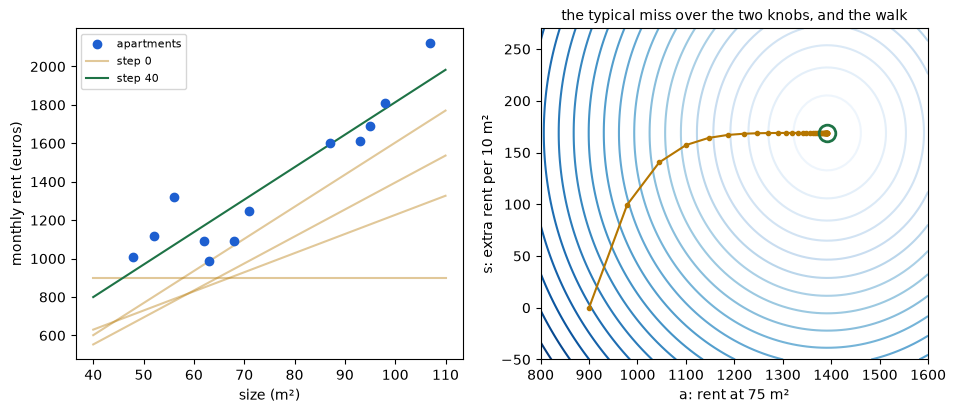

In [7]:
import random


def apartments(seed=1847):
    """Eleven sizes from 38 to 112 m^2 and a twelfth that makes the average exactly 75; rent = 16.5/m^2 + 150 + noise."""
    rng = random.Random(seed)
    while True:
        sizes = [rng.randrange(38, 113) for _ in range(11)]
        last = 900 - sum(sizes)
        if 38 <= last <= 112 and last not in sizes:
            sizes.append(last)
            break
    rents = [int(round((16.5 * m + 150 + rng.gauss(0, 90)) / 10) * 10) for m in sizes]
    return sorted(zip(sizes, rents))


APTS = apartments()
TABLE = [(48, 1010), (52, 1120), (56, 1320), (62, 1090), (63, 990), (68, 1090),
         (71, 1250), (87, 1600), (93, 1610), (95, 1690), (98, 1810), (107, 2120)]
if APTS != TABLE:                  # a different random module: use the video's table
    print("note: this Python made different apartments; using the table from the video")
    APTS = TABLE
sizes, rents = [m for m, _ in APTS], [v for _, v in APTS]
n = len(APTS)
u = [(m - 75) / 10 for m in sizes]
print("apartments (m^2, euros):", APTS)


def error(a, s):
    return sum((a + s * t - v) ** 2 for t, v in zip(u, rents)) / n


def slopes(a, s):
    miss = [a + s * t - v for t, v in zip(u, rents)]
    return 2 * sum(miss) / n, 2 * sum(q * t for q, t in zip(miss, u)) / n


U = [Fr(m - 75, 10) for m in sizes]
var_u = sum(t * t for t in U) / n
best_a = Fr(sum(rents), n)
best_s = sum(t * v for t, v in zip(U, rents)) / n / var_u
print(f"exact best line: a = {best_a} = {float(best_a):.4f}, s = {best_s} = {float(best_s):.4f}, "
      f"typical miss {math.sqrt(error(float(best_a), float(best_s))):.2f}")

eta, (a, s) = 0.08, (900.0, 0.0)
path = []
while True:
    path.append((a, s))
    if abs(a - float(best_a)) < 0.5 and abs(s - float(best_s)) < 0.05:
        break
    ga, gs = slopes(a, s)
    a, s = a - eta * ga, s - eta * gs
for k in [0, 1, 2, 5, 10, 20, len(path) - 1]:
    a, s = path[k]
    print(f"step {k:>2}: a = {a:8.2f}  s = {s:7.2f}  typical miss {math.sqrt(error(a, s)):6.1f}")
print(f"gap after {len(path) - 1} steps: a {path[-1][0] - float(best_a):+.2f} euros, "
      f"predicted {(900 - float(best_a)) * (1 - 2 * eta) ** (len(path) - 1):+.2f} (each step multiplies it by {1 - 2 * eta:.2f})")

if plt:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))
    ax1.scatter(sizes, rents, color="#1D5FD0", zorder=3, label="apartments")
    for k in (0, 1, 2, 5, len(path) - 1):
        a, s = path[k]
        last = k == len(path) - 1
        ax1.plot([40, 110], [a + s * (40 - 75) / 10, a + s * (110 - 75) / 10], color="#1E7346" if last else "#B57600",
                 alpha=1 if last else 0.4, label=f"step {k}" if k in (0, len(path) - 1) else None)
    ax1.set_xlabel("size (m²)")
    ax1.set_ylabel("monthly rent (euros)")
    ax1.legend(fontsize=8)
    A = [800 + i * 10 for i in range(81)]
    S = [-50 + i * 4 for i in range(81)]
    ax2.contour(A, S, [[math.sqrt(error(a, s)) for a in A] for s in S], levels=20, cmap="Blues")
    ax2.plot([p[0] for p in path], [p[1] for p in path], "o-", ms=3, color="#B57600")
    ax2.plot(float(best_a), float(best_s), "o", mfc="none", mec="#1E7346", ms=12, mew=2)
    ax2.set_xlabel("a: rent at 75 m²")
    ax2.set_ylabel("s: extra rent per 10 m²")
    ax2.set_title("the typical miss over the two knobs, and the walk", fontsize=10)
    plt.show()

## 6. The usual knobs: a long thin valley

Write the same line as rent \(= b + w \cdot \text{size}\). The error bowl's two curvatures become
0.122843 and 11,988: 97,590 times more curved one
way. With a safe step for the steep direction, each step shrinks the gap along the valley by a factor of only
\(1 - 1/97{,}590\), and our run needed 738,888 steps to get
within half a euro. The cell prints the gap as the walk crawls (with `FULL = False` it stops after
100,000 steps).

In [8]:
xbar = sum(sizes) / n
sx2 = sum(m * m for m in sizes) / n
tr, det = 2 + 2 * sx2, 4 * sx2 - (2 * xbar) ** 2
lo, hi = tr / 2 - math.sqrt(tr * tr / 4 - det), tr / 2 + math.sqrt(tr * tr / 4 - det)
print(f"curvatures {lo:.6f} and {hi:.2f}: {hi / lo:,.0f} times more curved across than along")
step = 1 / hi
best_b, best_w = float(best_a - best_s * Fr(75, 10)), float(best_s / 10)
b, w = 900.0, 0.0
checkpoints = {1, 10, 100, 1_000, 10_000, 100_000, 500_000}
for k in range(LONG_CAP + 1):
    if k in checkpoints:
        print(f"step {k:>7,}: b = {b:9.3f} (best {best_b:.3f})   w = {w:7.4f} (best {best_w:.4f})")
    if abs(b - best_b) < 0.5 and abs(w - best_w) < 0.005:
        print(f"within half a euro after {k:,} steps")
        break
    res = [b + w * m - v for m, v in zip(sizes, rents)]
    gb, gw = 2 * sum(res) / n, 2 * sum(q * m for q, m in zip(res, sizes)) / n
    b, w = b - step * gb, w - step * gw
else:
    print(f"not there after {LONG_CAP:,} steps (set FULL = True to run it to the end)")

curvatures 0.122843 and 11988.21: 97,590 times more curved across than along
step       1: b =   900.082 (best 124.238)   w =  7.1898 (best 16.8990)
step      10: b =   900.010 (best 124.238)   w =  7.1907 (best 16.8990)
step     100: b =   899.295 (best 124.238)   w =  7.1997 (best 16.8990)
step   1,000: b =   892.180 (best 124.238)   w =  7.2887 (best 16.8990)
step  10,000: b =   824.526 (best 124.238)   w =  8.1354 (best 16.8990)


step 100,000: b =   402.694 (best 124.238)   w = 13.4143 (best 16.8990)
not there after 100,000 steps (set FULL = True to run it to the end)


## 7. The family: how many apartments per step, and what the step remembers

Every step of section 5 averaged all 12 apartments' slopes: **batch** gradient descent. Real training
reads a few examples per step instead. **Stochastic** gradient descent takes one apartment per step, the next one in
an order shuffled once per epoch (one pass through all twelve, seed 7);
**mini-batch** takes the next 4. The "line gap" is how far a line is
from the best one, in euros: \(\sqrt{E - E_{\text{best}}}\). With the same \(\eta = 0.08\), our
one-apartment run never got within half a euro in 100 epochs; over the last
50 it hovered 121.71 euros from the
best line (root mean square). With four per step: 30.75, about
4 times
calmer. Let the step shrink, \(\eta_k = 0.08 / (1 + k/12)\) after \(k\)
steps, and both settle: within half a euro at every step from step 43,267
(one per step) and 10,388 (four per step) on.

each apartment's own slope at the best line (the average is zero, these aren't):
  (-149, +403)  (-234, +538)  (-499, +948)  (+164, -213)  (+398, -477)  (+367, -257)  (+148, -59)  (-11, -13)  (+172, +309)  (+79, +159)  (-59, -136)  (-375, -1200)
1 per step, eta 0.08: within half a euro 0 times in 1200 steps; last 50 epochs: line gap 121.71 typical, up to 332.86
4 per step, eta 0.08: within half a euro 0 times in 300 steps; last 50 epochs: line gap 30.75 typical, up to 83.02
1 per step, shrinking eta: first within at step 337, within at every step from 43,267 on (of 120,000)


4 per step, shrinking eta: first within at step 214, within at every step from 10,388 on (of 30,000)


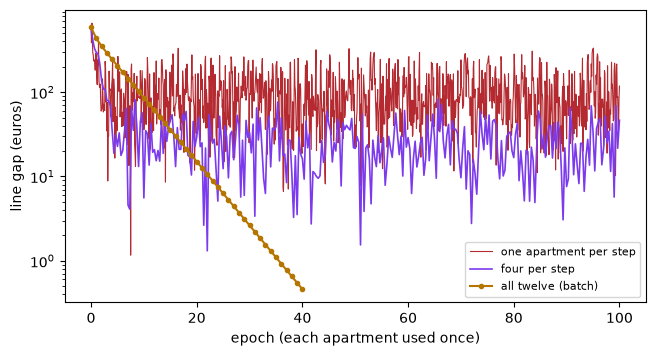

In [9]:
A, S, VU = float(best_a), float(best_s), float(var_u)


def gap(a, s):
    """sqrt(E - best E): the knobs don't mix, so it is (a - A)^2 + var(u) (s - S)^2 under the root."""
    return math.sqrt((a - A) ** 2 + VU * (s - S) ** 2)


def within(a, s):
    return abs(a - A) < 0.5 and abs(s - S) < 0.05


def slope_on(a, s, idx):
    res = [a + s * u[i] - rents[i] for i in idx]
    return 2 * sum(res) / len(idx), 2 * sum(q * u[i] for q, i in zip(res, idx)) / len(idx)


def shuffled(size, eta_at, epochs, seed=7):
    rng = random.Random(seed)
    a, s, k, pts = 900.0, 0.0, 0, [(900.0, 0.0)]
    for _ in range(epochs):
        order = list(range(n))
        rng.shuffle(order)
        for j in range(0, n, size):
            ga, gs = slope_on(a, s, order[j:j + size])
            eta = eta_at(k)
            a, s, k = a - eta * ga, s - eta * gs, k + 1
            pts.append((a, s))
    return pts


print("each apartment's own slope at the best line (the average is zero, these aren't):")
print("  " + "  ".join(f"({ga:+.0f}, {gs:+.0f})" for ga, gs in (slope_on(A, S, [i]) for i in range(n))))
runs = {}
for size in (1, 4):
    pts = shuffled(size, lambda k: 0.08, 100)
    tail = [gap(*p) for p in pts[50 * (n // size):]]
    runs[size] = pts
    print(f"{size} per step, eta 0.08: within half a euro {sum(within(*p) for p in pts)} times in {len(pts) - 1} steps;"
          f" last 50 epochs: line gap {math.sqrt(sum(g * g for g in tail) / len(tail)):.2f} typical, up to {max(tail):.2f}")
for size in (1, 4):
    pts = shuffled(size, lambda k: 0.08 / (1 + k / 12), 10_000)
    last_out = max(k for k, p in enumerate(pts) if not within(*p))
    print(f"{size} per step, shrinking eta: first within at step {next(k for k, p in enumerate(pts) if within(*p))},"
          f" within at every step from {last_out + 1:,} on (of {len(pts) - 1:,})")

if plt:
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.semilogy([k / n for k in range(len(runs[1]))], [gap(*p) for p in runs[1]], lw=0.8, color="#B42A30",
                label="one apartment per step")
    ax.semilogy([4 * k / n for k in range(len(runs[4]))], [gap(*p) for p in runs[4]], lw=1.2, color="#7C3AED",
                label="four per step")
    ax.semilogy(range(len(path)), [gap(*p) for p in path], "o-", ms=3, color="#B57600", label="all twelve (batch)")
    ax.set_xlabel("epoch (each apartment used once)")
    ax.set_ylabel("line gap (euros)")
    ax.legend(fontsize=8)
    plt.show()

**Momentum**, the heavy ball: \(v \leftarrow \beta v + \nabla f\), then \(x \leftarrow x - \eta v\), with
\(\beta = 0.9\). On the landscape, from the third start where the plain walk stopped in
the small dip, our heavy ball (\(\eta = 0.15\)) was past the dip by step
11, in the deep valley by step 20, and settled there after
163 steps of swinging. On the usual knobs of section 6 the memory piles the small steps along
the valley up: 73,827 steps instead of 738,888.

plain walk from (0.6, -2.6): 19 steps, stops at height -0.2485 (the dip)
heavy ball from (0.6, -2.6): 163 steps, settles at height -1.0237; past the dip at step 11, in the deep valley at step 20
its height every 10 steps: +0.43 -0.16 -1.02 -1.01 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02 -1.02


heavy ball on the usual knobs (eta 8.34153e-05): within half a euro after 73,827 steps


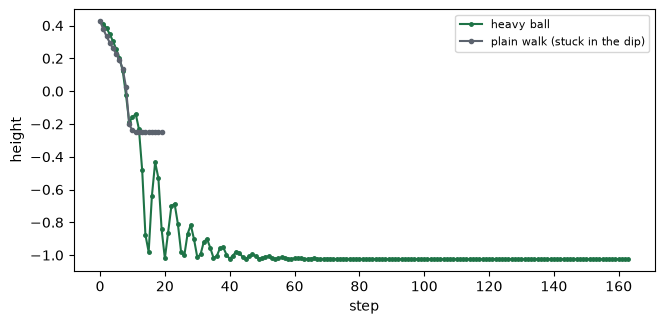

In [10]:
def heavy(x, y, eta, beta, tol=1e-3, cap=5000):
    path, vx, vy = [(x, y)], 0.0, 0.0
    for _ in range(cap):
        gx, gy = gradient(x, y)
        if math.hypot(gx, gy) < tol and math.hypot(vx, vy) < tol:
            break
        vx, vy = beta * vx + gx, beta * vy + gy
        x, y = x - eta * vx, y - eta * vy
        path.append((x, y))
    return path


ball = heavy(*TRAP_START, 0.15, 0.9)
print(f"plain walk from {TRAP_START}: {len(trap) - 1} steps, stops at height {land(*trap[-1]):.4f} (the dip)")
print(f"heavy ball from {TRAP_START}: {len(ball) - 1} steps, settles at height {land(*ball[-1]):.4f}; "
      f"past the dip at step {next(k for k, p in enumerate(ball) if p[1] > bottoms['dip'][1] + 0.3)}, "
      f"in the deep valley at step {next(k for k, p in enumerate(ball) if math.dist(p, bottoms['deep']) < 0.05)}")
print("its height every 10 steps:", " ".join(f"{land(*p):+.2f}" for p in ball[::10]))

xbar, sx2 = sum(sizes) / n, sum(m * m for m in sizes) / n
tr, det = 2 + 2 * sx2, 4 * sx2 - (2 * xbar) ** 2
eta_raw = round(1 / (tr / 2 + math.sqrt(tr * tr / 4 - det)), 10)    # the plain walk's step on the usual knobs
b, w, vb, vw = 900.0, 0.0, 0.0, 0.0
for k in range(1, 200_001):
    res = [b + w * m - v for m, v in zip(sizes, rents)]
    gb, gw = 2 * sum(res) / n, 2 * sum(q * m for q, m in zip(res, sizes)) / n
    vb, vw = 0.9 * vb + gb, 0.9 * vw + gw
    b, w = b - eta_raw * vb, w - eta_raw * vw
    if abs(b - best_b) < 0.5 and abs(w - best_w) < 0.005:
        print(f"heavy ball on the usual knobs (eta {eta_raw}): within half a euro after {k:,} steps")
        break

if plt:
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.plot(range(len(ball)), [land(*p) for p in ball], "o-", ms=2.5, color="#1E7346", label="heavy ball")
    ax.plot(range(len(trap)), [land(*p) for p in trap], "o-", ms=3, color="#5C636E", label="plain walk (stuck in the dip)")
    ax.set_xlabel("step")
    ax.set_ylabel("height")
    ax.legend(fontsize=8)
    plt.show()

**Adam** gives each knob its own step size: it keeps a running average \(m\) of each knob's slope and \(s\) of its
square, and steps \(\eta\, m / (\sqrt{s} + \varepsilon)\), about \(\eta\) whenever the slope keeps its sign,
however big the slope is. Our run, on the usual knobs with \(\eta = 1\),
\(\beta_1 = 0.9\), \(\beta_2 = 0.999\): within half a euro at step
3,117. With \(\eta\) fixed it didn't stay: over 20,000 steps it was
thrown out 24 times, first at step 6,531. Watch each
knob's step size \(\eta / \sqrt{s}\) grow once the slopes have nearly vanished.

step     1: line gap   515.60   step size for b 0.00102, for w 1.16e-05
step   100: line gap   187.08   step size for b 0.00443, for w 5.87e-05
step  1000: line gap    70.15   step size for b 0.0123, for w 0.000237
step  3000: line gap     0.18   step size for b 0.0391, for w 0.000791
step  5000: line gap     0.00   step size for b 0.109, for w 0.0022
step  6000: line gap     0.00   step size for b 0.18, for w 0.00363
step  6500: line gap     0.00   step size for b 0.231, for w 0.00467
step  6535: line gap    76.28   step size for b 0.218, for w 0.00397
step  6600: line gap     1.51   step size for b 0.0803, for w 0.00104
within half a euro first after 3,117 steps; thrown out 24 times, first at step 6,531; the biggest line gap after that: 76.61 euros


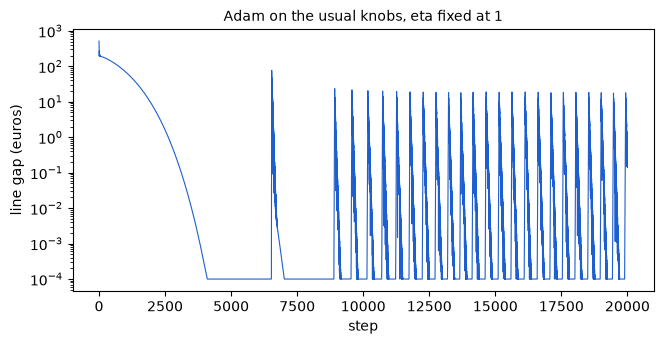

In [11]:
th, m1, m2 = [900.0, 0.0], [0.0, 0.0], [0.0, 0.0]
gaps, inside = [], [False]                    # inside[k]: the walk's half-a-euro test after k steps
for k in range(1, 20_001):
    res = [th[0] + th[1] * m - v for m, v in zip(sizes, rents)]
    g = (2 * sum(res) / n, 2 * sum(q * m for q, m in zip(res, sizes)) / n)
    for i in range(2):
        m1[i] = 0.9 * m1[i] + (1 - 0.9) * g[i]               # running average of the slope
        m2[i] = 0.999 * m2[i] + (1 - 0.999) * g[i] ** 2      # running average of the slope squared
        th[i] -= 1.0 * (m1[i] / (1 - 0.9 ** k)) / (math.sqrt(m2[i] / (1 - 0.999 ** k)) + 1e-8)
    gaps.append(gap(th[0] + 75 * th[1], 10 * th[1]))
    inside.append(abs(th[0] - best_b) < 0.5 and abs(th[1] - best_w) < 0.005)
    if k in (1, 100, 1000, 3000, 5000, 6000, 6500, 6535, 6600):
        sb, sw = (math.sqrt(m2[i] / (1 - 0.999 ** k)) for i in range(2))
        print(f"step {k:>5}: line gap {gaps[-1]:8.2f}   step size for b {1 / sb:.3g}, for w {1 / sw:.3g}")
exits = [k for k in range(1, len(inside)) if inside[k - 1] and not inside[k]]
bursts = sum(1 for i, e in enumerate(exits) if i == 0 or e - exits[i - 1] >= 300)   # exits < 300 apart: one burst
print(f"within half a euro first after {inside.index(True):,} steps; thrown out {bursts} times, first at step "
      f"{exits[0]:,}; the biggest line gap after that: {max(gaps[exits[0] - 1:]):.2f} euros")

if plt:
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.semilogy(range(1, len(gaps) + 1), [max(g_, 1e-4) for g_ in gaps], lw=0.8, color="#1D5FD0")
    ax.set_xlabel("step")
    ax.set_ylabel("line gap (euros)")
    ax.set_title("Adam on the usual knobs, eta fixed at 1", fontsize=10)
    plt.show()

## Your turn

Two experiments, each changing one thing.

1. **A step size between the limits.** For the line, \(a\)'s limit is 1 and \(s\)'s is
   0.271616. Set `eta = 0.3` below: which knob settles, which one runs away, and what does the line do?
2. **How much memory?** The heavy ball rolled through the small dip with \(\beta = 0.9\). Set
   `beta` to 0 (no memory: the plain walk), 0.5 and 0.8. Which ones still roll through, and how many steps does
   each need to settle?

In [12]:
eta = 0.3                          # experiment 1: try 0.25, 0.27, 0.28, 0.3
a, s = 900.0, 0.0
for k in range(12):
    ga, gs = slopes(a, s)
    a, s = a - eta * ga, s - eta * gs
    print(f"step {k + 1:>2}: a = {a:9.2f}   s = {s:12.2f}")

step  1: a =   1195.00   s =       373.30
step  2: a =   1313.00   s =       -78.02
step  3: a =   1360.20   s =       467.63
step  4: a =   1379.08   s =      -192.06
step  5: a =   1386.63   s =       605.50
step  6: a =   1389.65   s =      -358.75
step  7: a =   1390.86   s =       807.03
step  8: a =   1391.34   s =      -602.40
step  9: a =   1391.54   s =      1101.60
step 10: a =   1391.62   s =      -958.53
step 11: a =   1391.65   s =      1532.17
step 12: a =   1391.66   s =     -1479.09


In [13]:
for beta in (0.0, 0.5, 0.8, 0.9):  # experiment 2: the same start and step as the heavy ball above
    p = heavy(*TRAP_START, 0.15, beta)
    where = min(bottoms, key=lambda name: math.dist(p[-1], bottoms[name]))
    print(f"beta = {beta}: {len(p) - 1:>4} steps, ends in the {where} bottom, height {land(*p[-1]):+.4f}")

beta = 0.0:   41 steps, ends in the dip bottom, height -0.2485
beta = 0.5:   37 steps, ends in the dip bottom, height -0.2485
beta = 0.8:   86 steps, ends in the deep bottom, height -1.0237
beta = 0.9:  163 steps, ends in the deep bottom, height -1.0237
